<a href="https://colab.research.google.com/github/sasasaida/smsspamdetection/blob/main/SMS_Spam_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Classification: Accuracy-Focused SVM

This version focuses on improving test-set accuracy. It preserves useful SMS signals such as numbers, punctuation, capitalization, URLs, and repeated characters instead of aggressively deleting them. It combines word-level and character-level TF-IDF features and tunes a Linear SVM using stratified cross-validation.

**Important:** Actual accuracy is only known after running the notebook on the dataset. Do not report a score before running it.

In [1]:
!pip -q install scikit-learn pandas matplotlib seaborn

In [4]:
!pip install -q kagglehub

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42

## 1. Load the dataset

Upload the Kaggle `spam.csv` file if it is not already in the notebook environment. The loader accepts either `spam.csv` or `SMS.csv` and uses the standard UCI/Kaggle columns (`v1`, `v2`).

In [6]:
path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

print("Dataset downloaded to:", path)

# Find the CSV file in the downloaded dataset
csv_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower() in ["spam.csv", "sms.csv"]:
            csv_files.append(os.path.join(root, file))

if not csv_files:
    raise FileNotFoundError(
        "Could not find spam.csv or SMS.csv in the Kaggle dataset."
    )

filename = csv_files[0]
df = pd.read_csv(filename, encoding="latin-1")

# Support both common CSV formats
if {"v1", "v2"}.issubset(df.columns):
    df = df[["v1", "v2"]].rename(
        columns={"v1": "label", "v2": "message"}
    )
elif {"label", "message"}.issubset(df.columns):
    df = df[["label", "message"]]
else:
    raise ValueError(
        "Expected columns v1/v2 or label/message. Check the CSV format."
    )

# Clean the dataset
df = df.dropna(subset=["label", "message"]).copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df = df[df["label"].isin(["ham", "spam"])]
df["message"] = df["message"].astype(str)

# Remove exact duplicate rows
df = df.drop_duplicates(
    subset=["label", "message"]
).reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df["label"].value_counts())
df.head()

Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.
Dataset downloaded to: /kaggle/input/sms-spam-collection-dataset
Dataset shape: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Train/test split

The test set is held out and is not used for tuning. Stratification keeps the ham/spam proportions similar in both sets.

In [7]:
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training messages: {len(X_train)}")
print(f"Test messages: {len(X_test)}")

Training messages: 4135
Test messages: 1034


## 3. Word + character TF-IDF with Linear SVM

Word features learn informative words and short phrases. Character n-grams can capture spelling variations, unusual formatting, and patterns in promotional or suspicious messages. We use the original text rather than removing digits and punctuation, since those can be useful spam clues.

In [8]:
features = FeatureUnion([
    ("word_tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        analyzer="word",
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True,
        max_features=100000
    )),
    ("char_tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=150000
    ))
])

pipeline = Pipeline([
    ("features", features),
    ("svm", LinearSVC(max_iter=10000))
])

param_grid = {
    "svm__C": [0.1, 0.3, 1, 2, 5, 10],
    "svm__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best 5-fold CV accuracy: {search.best_score_:.4%}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'svm__C': 0.3, 'svm__class_weight': 'balanced'}
Best 5-fold CV accuracy: 98.9843%


## 4. Final test-set results

These metrics are calculated on the held-out test set, which was not used to choose hyperparameters.

Test accuracy: 98.6460%
\nClassification report:
              precision    recall  f1-score   support

         ham     0.9858    0.9989    0.9923       903
        spam     0.9916    0.9008    0.9440       131

    accuracy                         0.9865      1034
   macro avg     0.9887    0.9498    0.9681      1034
weighted avg     0.9865    0.9865    0.9862      1034



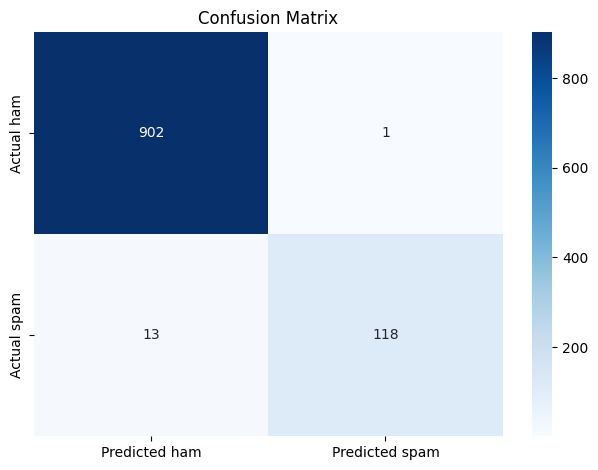

In [9]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_accuracy:.4%}")
print("\\nClassification report:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted ham", "Predicted spam"],
    yticklabels=["Actual ham", "Actual spam"]
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 5. Optional: inspect mistakes

This helps identify the messages the model still gets wrong. It does not change the test score.

In [10]:
results = pd.DataFrame({
    "message": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(y_pred)
})
mistakes = results[results["actual"] != results["predicted"]]
print("Misclassified messages:", len(mistakes))
display(mistakes.head(30))

Misclassified messages: 14


,message,actual,predicted
230,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...,spam,ham
308,Hi its LUCY Hubby at meetins all day Fri & I w...,spam,ham
326,Missed call alert. These numbers called but le...,spam,ham
329,SMS. ac sun0819 posts HELLO:\You seem cool,spam,ham
437,Babe: U want me dont u baby! Im nasty and have...,spam,ham
456,Check Out Choose Your Babe Videos @ sms.shsex....,spam,ham
486,In The Simpsons Movie released in July 2007 na...,spam,ham
544,Xmas & New Years Eve tickets are now on sale f...,spam,ham
690,"Latest News! Police station toilet stolen, cop...",spam,ham
726,Want explicit SEX in 30 secs? Ring 02073162414...,spam,ham


## 6. Predict new messages

The trained pipeline accepts raw SMS text directly; do not run a separate cleaning function.

In [11]:
def predict_sms(message):
    prediction = best_model.predict([str(message)])[0]
    return "Spam" if prediction == "spam" else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))

Spam
Ham
